# CSET485 – AI and Society · Assignment 1

**Name:** Rishant Ranjan  **Enrollment No.:** S24BCAU0036

**Dataset:** Adult Census Income (roll number ends in 6)  **Random seed:** 36 (last three digits, 036)

This notebook produces every number, table and chart used in the PDF report. Run it top to bottom
(`Kernel → Restart & Run All`). Outputs are written to `results/` (CSV tables and `numbers.json`)
and `figures/` (PNG charts).

Target: `y = 1` if income > $50K, else `0`.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 36
DATA = Path("data")
RES = Path("results"); RES.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
N = {}  # every number quoted in the report is stored here and saved to results/numbers.json

# chart styling (validated categorical slots 1 and 2, light mode, for print)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 200, "font.size": 9, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
})

## 0. Data loading

The UCI folder ships two files: `adult.data` (32,561 rows) and `adult.test` (16,281 rows). The test file
has a junk first line (`|1x3 Cross validator`) and labels ending in a full stop (`>50K.`). I join both files
and make my own 70/30 split with seed 36, as the brief asks. Missing values are coded as `?`.

In [2]:
COLS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
        "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week",
        "native_country", "income"]
train_raw = pd.read_csv(DATA / "adult.data", names=COLS, skipinitialspace=True, na_values="?")
test_raw = pd.read_csv(DATA / "adult.test", names=COLS, skipinitialspace=True, na_values="?", skiprows=1)
raw = pd.concat([train_raw, test_raw], ignore_index=True)
raw["income"] = raw["income"].str.rstrip(".")

N["raw_rows"] = len(raw)
N["raw_pos_rate"] = (raw.income == ">50K").mean()
print(raw.shape)
print(raw.income.value_counts())
print("\nMissing values per column:")
print(raw.isna().sum()[lambda s: s > 0])

(48842, 15)
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

Missing values per column:
workclass         2799
occupation        2809
native_country     857
dtype: int64


## 1. Data preprocessing

**Missing values.** Only three columns have `?`: `workclass` (2,799), `occupation` (2,809) and
`native_country` (857). They overlap heavily (almost every row missing `workclass` also misses `occupation`).
I drop rows with any missing value. Imputing a job title would invent the variable the model leans on most,
and the loss is small (see the count below).

**Duplicates.** I drop exact duplicate rows, including identical `fnlwgt`, because these are almost certainly
double entries.

**Dropped columns.**
- `fnlwgt` is a survey sampling weight, not a trait of the person.
- `education` is the same information as `education_num` (one-to-one mapping).
- `relationship` mostly recodes marital status × sex (`Husband` = married man, `Wife` = married woman). Keeping it
  next to `married` and `male` would split one effect across collinear columns.

**Rare categories.** `workclass = Without-pay` has 21 rows and only 2 high earners, which causes quasi-separation
in the logit, so I remove those rows. `occupation = Armed-Forces` (14 rows) is merged into `Protective-serv`.

**Categorical encoding.**
- `sex` → `male` (1 = Male).
- `marital_status` → `married` (1 = Married-civ-spouse or Married-AF-spouse).
- `native_country` → `native_us` (1 = United-States; 91% of rows, and 40 other countries are too thin to estimate).
- `race`, `workclass`, `occupation` → one-hot dummies with a reference level dropped
  (White, Private, Adm-clerical).

**Outliers and skew.** `capital_gain` is 0 for 92% of people and top-coded at 99,999 (229 rows);
`capital_loss` is 0 for 95%. I apply `log1p` to both instead of deleting rows, because the large values are real
and carry signal. `age` (17–90, 90 is top-coded) and `hours_per_week` (1–99) are kept as is; the IQR counts below
show how many points sit outside 1.5×IQR, and none of them are data errors.

**Scaling.** The five numeric features are z-scored with the **training-set** mean and SD, then the same
transform is applied to the test rows. Logistic coefficients for these features are therefore "change in log-odds
per one SD".

In [3]:
df = raw.dropna().copy()
N["rows_missing_dropped"] = len(raw) - len(df)
n_before = len(df)
df = df.drop_duplicates()
N["rows_duplicates_dropped"] = n_before - len(df)
N["rows_without_pay_dropped"] = int((df.workclass == "Without-pay").sum())
df = df[df.workclass != "Without-pay"]
df["occupation"] = df["occupation"].replace({"Armed-Forces": "Protective-serv"})

df["y"] = (df.income == ">50K").astype(int)
df["male"] = (df.sex == "Male").astype(int)
df["married"] = df.marital_status.isin(["Married-civ-spouse", "Married-AF-spouse"]).astype(int)
df["native_us"] = (df.native_country == "United-States").astype(int)
df["log_cap_gain"] = np.log1p(df.capital_gain)
df["log_cap_loss"] = np.log1p(df.capital_loss)
df = df.reset_index(drop=True)

N["clean_rows"] = len(df)
N["clean_pos_rate"] = df.y.mean()
N["capgain_zero_share"] = (df.capital_gain == 0).mean()
N["capgain_topcoded"] = int((df.capital_gain == 99999).sum())
N["caploss_zero_share"] = (df.capital_loss == 0).mean()

# IQR outlier counts (reported, not removed)
iqr_rows = []
for c in ["age", "hours_per_week", "capital_gain", "capital_loss", "education_num"]:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    out = ((df[c] < q1 - 1.5 * i) | (df[c] > q3 + 1.5 * i)).sum()
    iqr_rows.append({"feature": c, "min": df[c].min(), "q1": q1, "median": df[c].median(), "q3": q3,
                     "max": df[c].max(), "n_outside_1.5IQR": int(out), "pct": round(100 * out / len(df), 2)})
iqr = pd.DataFrame(iqr_rows)
iqr.to_csv(RES / "preprocessing_outliers.csv", index=False)
print(f"Dropped for missing values: {N['rows_missing_dropped']}, duplicates: {N['rows_duplicates_dropped']}, "
      f"Without-pay: {N['rows_without_pay_dropped']}  ->  final rows: {N['clean_rows']}")
print(f"Share earning >50K: {N['clean_pos_rate']:.4f}")
iqr

Dropped for missing values: 3620, duplicates: 47, Without-pay: 21  ->  final rows: 45154
Share earning >50K: 0.2480


,feature,min,q1,median,q3,max,n_outside_1.5IQR,pct
0,age,17,28.0,37.0,47.0,90,268,0.59
1,hours_per_week,1,40.0,40.0,45.0,99,11876,26.30
2,capital_gain,0,0.0,0.0,0.0,99999,3788,8.39
3,capital_loss,0,0.0,0.0,0.0,4356,2139,4.74
4,education_num,1,9.0,10.0,13.0,16,290,0.64


In [4]:
NUM = ["age", "education_num", "hours_per_week", "log_cap_gain", "log_cap_loss"]
X = pd.concat([
    df[NUM + ["male", "married", "native_us"]],
    pd.get_dummies(df.race, prefix="race").drop(columns="race_White"),
    pd.get_dummies(df.workclass, prefix="wc").drop(columns="wc_Private"),
    pd.get_dummies(df.occupation, prefix="occ").drop(columns="occ_Adm-clerical"),
], axis=1).astype(float)
y = df.y

# 70/30 split, seed 36, stratified so both halves keep the 24.8% positive rate
idx_tr, idx_te = train_test_split(df.index, test_size=0.30, random_state=SEED, stratify=y)
mu, sd = X.loc[idx_tr, NUM].mean(), X.loc[idx_tr, NUM].std()
Xs = X.copy()
Xs[NUM] = (X[NUM] - mu) / sd
Xc = sm.add_constant(Xs)

N["n_train"], N["n_test"] = len(idx_tr), len(idx_te)
N["n_features"] = X.shape[1]
N["sd_raw"] = sd.round(4).to_dict()
print(f"Train {len(idx_tr)}, test {len(idx_te)}, features {X.shape[1]}")
print("Training-set SD used for scaling:\n", sd.round(3))

Train 31607, test 13547, features 29
Training-set SD used for scaling:
 age               13.229
education_num      2.549
hours_per_week    11.991
log_cap_gain       2.464
log_cap_loss       1.592
dtype: float64


## Part 1 — Build

- **Model A**: OLS on the 0/1 target (a linear probability model).
- **Model B**: logistic regression.

Both are fit with `statsmodels` on the training split, without regularisation, using the same 29 features.

In [5]:
Xtr, Xte, ytr, yte = Xc.loc[idx_tr], Xc.loc[idx_te], y.loc[idx_tr], y.loc[idx_te]
model_a = sm.OLS(ytr, Xtr).fit()
model_b = sm.Logit(ytr, Xtr).fit(disp=0)

pred_a = model_a.predict(Xte)          # continuous score, can leave [0, 1]
prob_b = model_b.predict(Xte)          # probability in (0, 1)

median_a = float(np.median(pred_a))
flag_a = (pred_a >= median_a).astype(int)
flag_b = (prob_b >= 0.5).astype(int)

cm_ab = pd.crosstab(pd.Series(flag_a.values, name="Model A (≥ median)"),
                    pd.Series(flag_b.values, name="Model B (P ≥ 0.5)"))
cm_ab.index = ["A: low risk", "A: high risk"]; cm_ab.columns = ["B: low risk", "B: high risk"]
mismatch = int((flag_a != flag_b).sum())

N.update({
    "p1_median_a": median_a, "p1_mean_a": float(pred_a.mean()),
    "p1_a_below0": int((pred_a < 0).sum()), "p1_a_above1": int((pred_a > 1).sum()),
    "p1_flag_a": int(flag_a.sum()), "p1_flag_b": int(flag_b.sum()),
    "p1_mismatch": mismatch, "p1_mismatch_pct": mismatch / len(yte),
    "p1_a_hi_b_lo": int(((flag_a == 1) & (flag_b == 0)).sum()),
    "p1_a_lo_b_hi": int(((flag_a == 0) & (flag_b == 1)).sum()),
    "p1_both_hi": int(((flag_a == 1) & (flag_b == 1)).sum()),
    "p1_both_lo": int(((flag_a == 0) & (flag_b == 0)).sum()),
    "p1_test_pos_rate": float(yte.mean()),
    "p1_acc_a": accuracy_score(yte, flag_a), "p1_acc_b": accuracy_score(yte, flag_b),
    "p1_r2_a": float(model_a.rsquared), "p1_pseudo_r2_b": float(model_b.prsquared),
    "p1_logit_p_at_median_a": float(prob_b[(pred_a - median_a).abs().idxmin()]),
    "p1_corr_ab": float(np.corrcoef(pred_a, prob_b)[0, 1]),
})
# Where does Model A put the people Model B flags?
N["p1_b_flagged_min_a_score"] = float(pred_a[flag_b == 1].min())
# Precision of each rule against the real label
N["p1_prec_a"] = float(yte[flag_a == 1].mean()); N["p1_prec_b"] = float(yte[flag_b == 1].mean())
N["p1_recall_a"] = float(flag_a[yte == 1].mean()); N["p1_recall_b"] = float(flag_b[yte == 1].mean())

cm_ab.to_csv(RES / "part1_confusion_A_vs_B.csv")
print(f"Median Model A prediction: {median_a:.4f}")
print(f"Model A predictions < 0: {N['p1_a_below0']},  > 1: {N['p1_a_above1']}")
print(f"Flagged high risk: A = {N['p1_flag_a']}, B = {N['p1_flag_b']}")
print(f"Mismatched: {mismatch} of {len(yte)} ({100*mismatch/len(yte):.2f}%)")
print(f"Accuracy vs real label: A = {N['p1_acc_a']:.4f}, B = {N['p1_acc_b']:.4f}")
print(f"Precision: A = {N['p1_prec_a']:.4f}, B = {N['p1_prec_b']:.4f};  Recall: A = {N['p1_recall_a']:.4f}, B = {N['p1_recall_b']:.4f}")
cm_ab

Median Model A prediction: 0.2358
Model A predictions < 0: 2861,  > 1: 70
Flagged high risk: A = 6774, B = 2758
Mismatched: 4016 of 13547 (29.64%)
Accuracy vs real label: A = 0.7196, B = 0.8411
Precision: A = 0.4677, B = 0.7190;  Recall: A = 0.9429, B = 0.5902


,B: low risk,B: high risk
A: low risk,6773,0
A: high risk,4016,2758


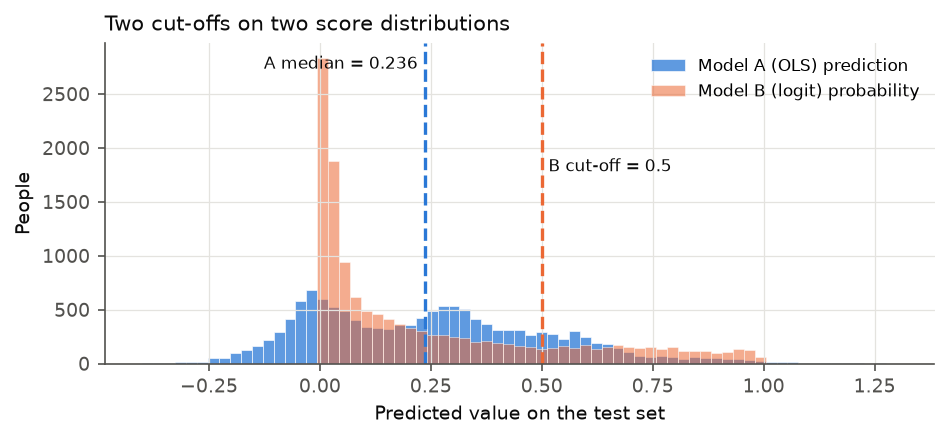

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
bins = np.linspace(-0.4, 1.3, 70)
ax.hist(pred_a, bins=bins, color=BLUE, alpha=0.75, label="Model A (OLS) prediction", edgecolor="white", linewidth=0.4)
ax.hist(prob_b, bins=bins, color=ORANGE, alpha=0.55, label="Model B (logit) probability", edgecolor="white", linewidth=0.4)
ax.axvline(median_a, color=BLUE, lw=1.6, ls="--")
ax.axvline(0.5, color=ORANGE, lw=1.6, ls="--")
ax.text(median_a - 0.015, ax.get_ylim()[1] * 0.92, f"A median = {median_a:.3f}", color=INK, fontsize=8, ha="right")
ax.text(0.515, ax.get_ylim()[1] * 0.60, "B cut-off = 0.5", color=INK, fontsize=8)
ax.set_xlabel("Predicted value on the test set"); ax.set_ylabel("People")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Two cut-offs on two score distributions", fontsize=10, color=INK, loc="left")
fig.tight_layout(); fig.savefig(FIG / "part1_prediction_distributions.png"); plt.show()

## Part 2.1 — Simpson's paradox hunt

Split variable: **marital status** (`married` = 1 vs 0). Key predictor: **`male`**.

I fit the logit on the full cleaned dataset (all 45,154 rows; `married` is a covariate in this model), then on
each subgroup (where `married` is constant, so it drops out). I also fit one pooled model with a `male × married`
interaction to test whether the two subgroup slopes really differ.

In [7]:
def logit(mask, drop=()):
    return sm.Logit(y[mask], Xc.loc[mask].drop(columns=list(drop))).fit(disp=0)

all_rows = pd.Series(True, index=df.index)
m_full = logit(all_rows)
m_unmar = logit(df.married == 0, drop=["married"])
m_mar = logit(df.married == 1, drop=["married"])

def row(name, m, n):
    ci = m.conf_int().loc["male"]
    return {"model": name, "n": n, "coef_male": m.params["male"], "ci_low": ci[0], "ci_high": ci[1],
            "p_value": m.pvalues["male"], "odds_ratio": np.exp(m.params["male"])}

simpson = pd.DataFrame([
    row("Full dataset", m_full, len(df)),
    row("Subgroup A: not married", m_unmar, int((df.married == 0).sum())),
    row("Subgroup B: married", m_mar, int((df.married == 1).sum())),
])
# formal test of the difference: interaction model
Xi = Xc.copy(); Xi["male_x_married"] = Xi.male * Xi.married
m_int = sm.Logit(y, Xi).fit(disp=0)
N["s_interaction_coef"] = float(m_int.params["male_x_married"])
N["s_interaction_ci"] = m_int.conf_int().loc["male_x_married"].tolist()
N["s_interaction_p"] = float(m_int.pvalues["male_x_married"])
for _, r in simpson.iterrows():
    k = {"Full dataset": "full", "Subgroup A: not married": "unmar", "Subgroup B: married": "mar"}[r.model]
    N[f"s_{k}_coef"], N[f"s_{k}_ci"], N[f"s_{k}_p"], N[f"s_{k}_or"], N[f"s_{k}_n"] = (
        r.coef_male, [r.ci_low, r.ci_high], r.p_value, r.odds_ratio, int(r.n))
simpson.to_csv(RES / "part2_1_simpson_coefficients.csv", index=False)

# raw (unadjusted) rates: the paradox is visible even without a model
raw_rates = df.groupby(["married", "sex"]).y.agg(["mean", "size"]).rename(columns={"mean": "share_>50K", "size": "n"})
overall = df.groupby("sex").y.mean()
N["s_raw_overall"] = overall.to_dict()
N["s_raw_by_group"] = {f"{'married' if m else 'unmarried'}_{s}": float(v) for (m, s), v in raw_rates["share_>50K"].items()}
N["s_share_married_by_sex"] = df.groupby("sex").married.mean().to_dict()
N["s_unadjusted_male_coef"] = float(sm.Logit(y, sm.add_constant(df[["male"]])).fit(disp=0).params["male"])
raw_rates.to_csv(RES / "part2_1_raw_rates.csv")

print(simpson.round(4).to_string(index=False))
print(f"\nInteraction male×married: {N['s_interaction_coef']:.4f}, 95% CI {np.round(N['s_interaction_ci'],4)}, p = {N['s_interaction_p']:.2e}")
print("\nRaw share earning >50K:\n", raw_rates.round(4))
print("\nShare married, by sex:", {k: round(v, 4) for k, v in N["s_share_married_by_sex"].items()})

                  model     n  coef_male  ci_low  ci_high  p_value  odds_ratio
           Full dataset 45154     0.1198  0.0378   0.2018   0.0042      1.1272
Subgroup A: not married 24093     0.6385  0.5072   0.7698   0.0000      1.8937
    Subgroup B: married 21061    -0.2901 -0.4019  -0.1784   0.0000      0.7482

Interaction male×married: -1.0852, 95% CI [-1.2428 -0.9276], p = 1.68e-41

Raw share earning >50K:
                 share_>50K      n
married sex                      
0       Female      0.0506  12443
        Male        0.0859  11650
1       Female      0.4659   2230
        Male        0.4530  18831

Share married, by sex: {'Female': 0.152, 'Male': 0.6178}


In [8]:
# other predictors that move across the split (for context in the report)
comp = pd.DataFrame({"full": m_full.params, "not_married": m_unmar.params, "p_not_married": m_unmar.pvalues,
                     "married": m_mar.params, "p_married": m_mar.pvalues}).drop(index=["const"])
comp.round(4).to_csv(RES / "part2_1_all_coefficients_by_subgroup.csv")
comp.round(3)

,full,not_married,p_not_married,married,p_married
age,0.386,0.639,0.000,0.304,0.000
education_num,0.735,0.797,0.000,0.700,0.000
hours_per_week,0.356,0.535,0.000,0.296,0.000
log_cap_gain,0.519,0.683,0.000,0.426,0.000
log_cap_loss,0.242,0.220,0.000,0.250,0.000
male,0.120,0.639,0.000,-0.290,0.000
married,2.377,NaN,NaN,NaN,NaN
native_us,0.203,-0.085,0.514,0.298,0.000
occ_Craft-repair,0.020,0.584,0.000,-0.092,0.206
occ_Exec-managerial,0.777,1.259,0.000,0.653,0.000


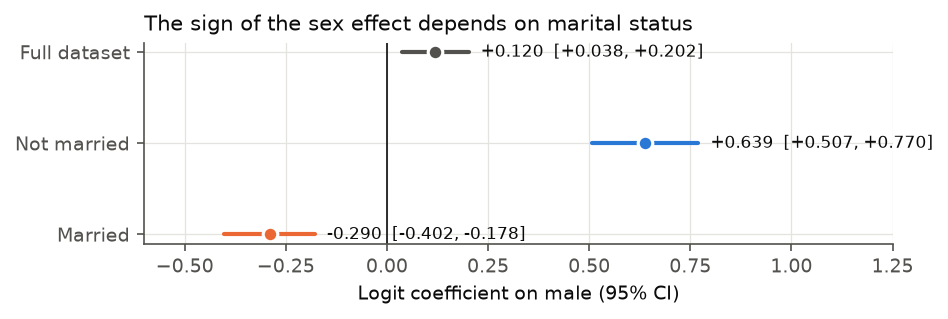

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 2.2))
labels = ["Full dataset", "Not married", "Married"]
for i, (m, c) in enumerate(zip([m_full, m_unmar, m_mar], [MUTED, BLUE, ORANGE])):
    lo, hi = m.conf_int().loc["male"]; b = m.params["male"]
    ax.plot([lo, hi], [i, i], color=c, lw=2, solid_capstyle="round")
    ax.plot(b, i, "o", color=c, ms=7, mec="white", mew=1.5)
    ax.text(hi + 0.03, i, f"{b:+.3f}  [{lo:+.3f}, {hi:+.3f}]", va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(range(3)); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlim(-0.6, 1.25); ax.set_xlabel("Logit coefficient on male (95% CI)")
ax.set_title("The sign of the sex effect depends on marital status", fontsize=10, color=INK, loc="left")
fig.tight_layout(); fig.savefig(FIG / "part2_1_simpson.png"); plt.show()

## Part 2.2 — Omitted-variable bias

Dropped variable: **`married`**. Marriage is linked to sex (in this sample 87% of married people are men, see
below), to age, and to income, so it is the obvious candidate confounder. I fit the full logit and the reduced
logit on all 45,154 rows and compare coefficients.

`% change = (reduced − full) / |full| × 100`.

In [10]:
m_red = sm.Logit(y, Xc.drop(columns="married")).fit(disp=0)
ovb = pd.DataFrame({"full_model": m_full.params, "without_married": m_red.params}).drop(index=["const", "married"])
ovb["abs_change"] = ovb.without_married - ovb.full_model
ovb["pct_change"] = 100 * ovb.abs_change / ovb.full_model.abs()
ovb["p_full"] = m_full.pvalues.drop(index=["const", "married"])
ovb = ovb.sort_values("pct_change", key=np.abs, ascending=False)
ovb.round(4).to_csv(RES / "part2_2_ovb_all.csv")

focus = ["male", "age", "hours_per_week", "education_num", "log_cap_gain", "race_Black", "occ_Exec-managerial"]
ovb_focus = ovb.loc[focus]
ovb_focus.round(4).to_csv(RES / "part2_2_ovb_focus.csv")
N["ovb_focus"] = ovb_focus[["full_model", "without_married", "pct_change"]].round(4).to_dict(orient="index")
N["ovb_married_coef_full"] = float(m_full.params["married"])
N["ovb_married_or_full"] = float(np.exp(m_full.params["married"]))
N["ovb_married_share_men"] = float(df.loc[df.married == 1, "male"].mean())
N["ovb_corr_married_male"] = float(df[["married", "male"]].corr().iloc[0, 1])
N["ovb_corr_married_age"] = float(df[["married", "age"]].corr().iloc[0, 1])
N["ovb_pseudo_r2_full"], N["ovb_pseudo_r2_red"] = float(m_full.prsquared), float(m_red.prsquared)
N["ovb_aic_full"], N["ovb_aic_red"] = float(m_full.aic), float(m_red.aic)
print(f"married coefficient in full model: {N['ovb_married_coef_full']:.4f} (odds ratio {N['ovb_married_or_full']:.2f})")
print(f"corr(married, male) = {N['ovb_corr_married_male']:.3f}, corr(married, age) = {N['ovb_corr_married_age']:.3f}")
print(f"share of married people who are men: {N['ovb_married_share_men']:.4f}")
print(f"pseudo-R2 full {N['ovb_pseudo_r2_full']:.4f} vs reduced {N['ovb_pseudo_r2_red']:.4f}")
ovb_focus.round(4)

married coefficient in full model: 2.3767 (odds ratio 10.77)
corr(married, male) = 0.437, corr(married, age) = 0.305
share of married people who are men: 0.8941
pseudo-R2 full 0.3896 vs reduced 0.2925


,full_model,without_married,abs_change,pct_change,p_full
male,0.1198,1.1675,1.0477,874.6914,0.0042
age,0.3857,0.5525,0.1668,43.2316,0.0000
hours_per_week,0.3561,0.3686,0.0125,3.5231,0.0000
education_num,0.7348,0.6519,-0.0829,-11.2778,0.0000
log_cap_gain,0.5191,0.4980,-0.0211,-4.0584,0.0000
race_Black,-0.1777,-0.3923,-0.2146,-120.7431,0.0034
occ_Exec-managerial,0.7774,0.8073,0.0300,3.8529,0.0000


In [11]:
print("Largest relative shifts among all predictors:")
ovb.head(8).round(4)

Largest relative shifts among all predictors:


,full_model,without_married,abs_change,pct_change,p_full
male,0.1198,1.1675,1.0477,874.6914,0.0042
occ_Craft-repair,0.0203,0.1522,0.1319,651.4339,0.7491
race_Asian-Pac-Islander,0.0114,0.0497,0.0383,335.6802,0.9038
race_Black,-0.1777,-0.3923,-0.2146,-120.7431,0.0034
occ_Transport-moving,-0.1290,-0.0052,0.1238,95.9712,0.1041
wc_Self-emp-inc,0.1843,0.3241,0.1398,75.8562,0.0069
wc_Local-gov,-0.1949,-0.0804,0.1145,58.7364,0.0007
race_Other,-0.1666,-0.2622,-0.0956,-57.4257,0.4150


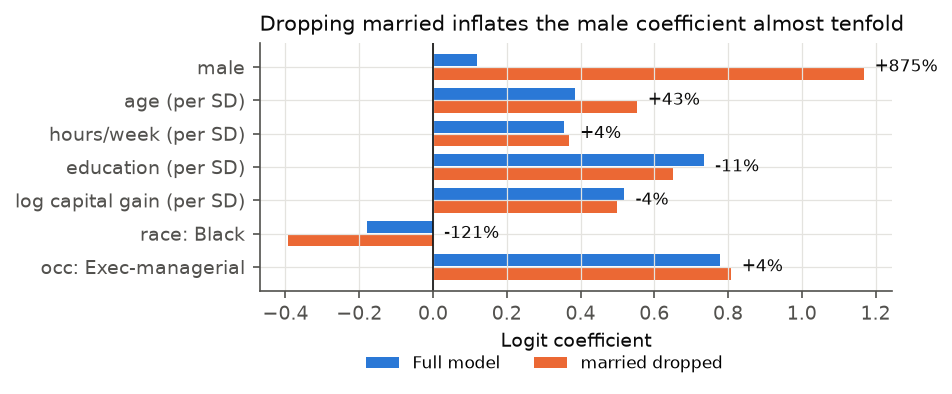

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
names = {"male": "male", "age": "age (per SD)", "hours_per_week": "hours/week (per SD)",
         "education_num": "education (per SD)", "log_cap_gain": "log capital gain (per SD)",
         "race_Black": "race: Black", "occ_Exec-managerial": "occ: Exec-managerial"}
ypos = np.arange(len(focus))
ax.barh(ypos - 0.2, ovb_focus.full_model, height=0.36, color=BLUE, label="Full model")
ax.barh(ypos + 0.2, ovb_focus.without_married, height=0.36, color=ORANGE, label="married dropped")
for i, f in enumerate(focus):
    v = max(ovb_focus.full_model[f], ovb_focus.without_married[f], 0)
    ax.text(v + 0.03, i, f"{ovb_focus["pct_change"][f]:+.0f}%", va="center", fontsize=8, color=INK)
ax.set_yticks(ypos); ax.set_yticklabels([names[f] for f in focus]); ax.invert_yaxis()
ax.axvline(0, color=INK, lw=0.8); ax.set_xlabel("Logit coefficient")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=2)
ax.set_title("Dropping married inflates the male coefficient almost tenfold", fontsize=10, color=INK, loc="left")
fig.tight_layout(); fig.savefig(FIG / "part2_2_ovb.png"); plt.show()

## Part 2.3 — Adversarial subset

Using Model B on the test set: confident false positives (P ≥ 0.75, y = 0) and confident false negatives
(P ≤ 0.25, y = 1). I sample 50 of them with seed 36 and compare them with the full test set.

In [13]:
T = df.loc[idx_te].copy()
T["p"] = prob_b
conf_fp = (T.p >= 0.75) & (T.y == 0)
conf_fn = (T.p <= 0.25) & (T.y == 1)
wrong = conf_fp | conf_fn
adv = T[wrong].sample(50, random_state=SEED)
adv.to_csv(RES / "part2_3_adversarial_50_rows.csv")

N.update({"adv_total": int(wrong.sum()), "adv_pct": float(wrong.mean()),
          "adv_fp_total": int(conf_fp.sum()), "adv_fn_total": int(conf_fn.sum()),
          "adv_n_hi_conf_pos": int((T.p >= 0.75).sum()), "adv_n_hi_conf_neg": int((T.p <= 0.25).sum())})

def profile(d):
    return pd.Series({
        "n": len(d), "mean age": d.age.mean(), "age < 30": (d.age < 30).mean(), "age ≥ 50": (d.age >= 50).mean(),
        "female": (d.male == 0).mean(), "white": (d.race == "White").mean(), "black": (d.race == "Black").mean(),
        "married": d.married.mean(), "education ≤ 10 yrs (HS/some college)": (d.education_num <= 10).mean(),
        "education ≥ 13 yrs (bachelor+)": (d.education_num >= 13).mean(), "hours > 40": (d.hours_per_week > 40).mean(),
        "capital gain = 0": (d.capital_gain == 0).mean(), "capital gain or loss > 0": ((d.capital_gain > 0) | (d.capital_loss > 0)).mean(),
        "actual >50K": d.y.mean(), "mean predicted P": d.p.mean()})

adv_fn, adv_fp = adv[adv.y == 1], adv[adv.y == 0]
prof = pd.DataFrame({"full test set": profile(T), "all confident errors": profile(T[wrong]),
                     "sample of 50": profile(adv), "  of which FN": profile(adv_fn), "  of which FP": profile(adv_fp)})
prof.round(3).to_csv(RES / "part2_3_profile.csv")
N["adv_profile"] = prof.round(4).to_dict()
print(f"Confident wrong predictions: {N['adv_total']} of {len(T)} ({100*N['adv_pct']:.2f}%)  "
      f"[FP {N['adv_fp_total']}, FN {N['adv_fn_total']}]")
print(f"FN rate inside P ≤ 0.25: {N['adv_fn_total']}/{N['adv_n_hi_conf_neg']};  FP rate inside P ≥ 0.75: {N['adv_fp_total']}/{N['adv_n_hi_conf_pos']}")
prof.round(3)

Confident wrong predictions: 751 of 13547 (5.54%)  [FP 179, FN 572]
FN rate inside P ≤ 0.25: 572/8715;  FP rate inside P ≥ 0.75: 179/1211


,full test set,all confident errors,sample of 50,of which FN,of which FP
n,13547.000,751.000,50.000,39.000,11.000
mean age,38.462,42.957,39.720,37.410,47.909
age < 30,0.287,0.121,0.160,0.154,0.182
age ≥ 50,0.207,0.278,0.140,0.051,0.455
female,0.320,0.224,0.260,0.308,0.091
white,0.860,0.879,0.940,0.923,1.000
black,0.095,0.075,0.040,0.051,0.000
married,0.465,0.631,0.640,0.564,0.909
education ≤ 10 yrs (HS/some college),0.676,0.599,0.580,0.718,0.091
education ≥ 13 yrs (bachelor+),0.251,0.340,0.300,0.179,0.727


In [14]:
print("Occupation mix of the 50 vs test set:")
pd.DataFrame({"sample_50": adv.occupation.value_counts(normalize=True),
              "test_set": T.occupation.value_counts(normalize=True)}).fillna(0).round(3).sort_values("sample_50", ascending=False)

Occupation mix of the 50 vs test set:


,sample_50,test_set
occupation,,
Prof-specialty,0.20,0.134
Adm-clerical,0.16,0.120
Exec-managerial,0.14,0.132
Sales,0.10,0.116
Craft-repair,0.08,0.133
Machine-op-inspct,0.06,0.065
Other-service,0.06,0.109
Protective-serv,0.06,0.022
Farming-fishing,0.04,0.035


Two checks on *why* the model fails here:

1. **Calibration.** If the model is calibrated, a band with average P ≈ 0.16 should contain about 16% positives.
   Confident false negatives would then be the expected tail of an uncertain band, not a bug.
2. **Capital gain is not monotone.** The model enters `log(1 + capital_gain)` as one straight line in log-odds.
   The table below shows what the raw data says for each band of capital gain.

In [15]:
bands = [0, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 1.0001]
cal = T.groupby(pd.cut(T.p, bands, right=False)).agg(n=("y", "size"), mean_pred=("p", "mean"), actual_rate=("y", "mean"))
cal.round(4).to_csv(RES / "part2_3_calibration.csv")
N["adv_calibration"] = {str(k): v for k, v in cal.round(4).to_dict(orient="index").items()}

cg_band = pd.cut(df.capital_gain, [-1, 0, 3000, 5100, 7000, 100000],
                 labels=["0", "1–3,000", "3,001–5,100", "5,101–7,000", "> 7,000"])
cg = df.groupby(cg_band).agg(n=("y", "size"), share_over_50K=("y", "mean"))
# what the fitted logit adds to the log-odds for an example gain inside each band, versus a gain of 0
cg["example_gain"] = [0, 2000, 4000, 6000, 15000]
cg["model_logit_shift_vs_0"] = model_b.params["log_cap_gain"] * np.log1p(cg.example_gain) / sd["log_cap_gain"]
cg.round(4).to_csv(RES / "part2_3_capital_gain_bands.csv")
N["adv_capgain_bands"] = {str(k): v for k, v in cg.round(4).to_dict(orient="index").items()}
N["adv_logit_coef_capgain"] = float(model_b.params["log_cap_gain"])
N["adv_logit_coef_married"] = float(model_b.params["married"])
N["adv_logit_coef_edu"] = float(model_b.params["education_num"])
N["adv_fn_mean_p"] = float(adv_fn.p.mean())
print(cal.round(3)); print(); print(cg.round(3))

                n  mean_pred  actual_rate
p                                        
[0.0, 0.05)  5011      0.019        0.013
[0.05, 0.1)  1398      0.072        0.061
[0.1, 0.25)  2306      0.167        0.182
[0.25, 0.5)  2074      0.361        0.388
[0.5, 0.75)  1547      0.626        0.615
[0.75, 0.9)   755      0.819        0.805
[0.9, 1.0)    456      0.948        0.930

                  n  share_over_50K  example_gain  model_logit_shift_vs_0
capital_gain                                                             
0             41366           0.213             0                   0.000
1–3,000         614           0.000          2000                   1.584
3,001–5,100     954           0.286          4000                   1.728
5,101–7,000     259           0.645          6000                   1.812
> 7,000        1961           0.987         15000                   2.003


In [16]:
# Does a non-linear capital-gain encoding fix the confident false positives?
def add_cg_bins(Xframe, idx):
    out = Xframe.copy()
    g = df.loc[idx, "capital_gain"]
    out["cg_1_3000"] = ((g > 0) & (g <= 3000)).astype(float)
    out["cg_3001_7000"] = ((g > 3000) & (g <= 7000)).astype(float)
    out["cg_gt_7000"] = (g > 7000).astype(float)
    return out.drop(columns="log_cap_gain")

model_b2 = sm.Logit(ytr, add_cg_bins(Xtr, idx_tr)).fit(disp=0, method="bfgs", maxiter=2000)
prob_b2 = model_b2.predict(add_cg_bins(Xte, idx_te))
fp2 = ((prob_b2 >= 0.75) & (yte == 0)); fn2 = ((prob_b2 <= 0.25) & (yte == 1))
N["adv_bins_fp"], N["adv_bins_fn"] = int(fp2.sum()), int(fn2.sum())
N["adv_bins_acc"] = accuracy_score(yte, (prob_b2 >= 0.5).astype(int))
N["adv_fp_fixed_in_sample"] = int((prob_b2.loc[adv_fp.index] < 0.75).sum())
print(f"With capital-gain bins: confident FP {N['adv_bins_fp']} (was {N['adv_fp_total']}), "
      f"confident FN {N['adv_bins_fn']} (was {N['adv_fn_total']}), accuracy {N['adv_bins_acc']:.4f} (was {N['p1_acc_b']:.4f})")
print(f"Of the {len(adv_fp)} confident FPs in the sample of 50, {N['adv_fp_fixed_in_sample']} drop below 0.75 with the binned model")

With capital-gain bins: confident FP 136 (was 179), confident FN 543 (was 572), accuracy 0.8499 (was 0.8411)
Of the 11 confident FPs in the sample of 50, 5 drop below 0.75 with the binned model


## Part 2.4 — Fairness trade-off

Sensitive variable: **sex**. Group A = Female, Group B = Male. Metrics are computed on the test set from Model B's
probabilities at thresholds 0.05, 0.15, …, 0.95.

- DP = P(Ŷ=1 | Female) / P(Ŷ=1 | Male)
- EO = min(TPR_F / TPR_M, FPR_F / FPR_M)
- PP = P(Y=1 | Ŷ=1, Female) / P(Y=1 | Ŷ=1, Male)

A ratio is left blank (NaN) if its denominator is zero.

In [17]:
def rates(yt, yp):
    tp = ((yp == 1) & (yt == 1)).sum(); fp = ((yp == 1) & (yt == 0)).sum()
    pos, neg = (yt == 1).sum(), (yt == 0).sum()
    return {"sel": yp.mean(), "tpr": tp / pos if pos else np.nan, "fpr": fp / neg if neg else np.nan,
            "ppv": tp / (tp + fp) if (tp + fp) else np.nan}

def ratio(a, b):
    return a / b if (b and not np.isnan(b)) else np.nan

fem, mal = (T.male == 0).values, (T.male == 1).values
yv, pv = T.y.values, T.p.values
rows = []
for t in np.round(np.arange(0.05, 1.0, 0.10), 2):
    yp = (pv >= t).astype(int)
    rf, rm = rates(yv[fem], yp[fem]), rates(yv[mal], yp[mal])
    tpr_r, fpr_r = ratio(rf["tpr"], rm["tpr"]), ratio(rf["fpr"], rm["fpr"])
    rows.append({"threshold": t,
                 "DP": ratio(rf["sel"], rm["sel"]),
                 "EO": np.nanmin([tpr_r, fpr_r]) if not (np.isnan(tpr_r) and np.isnan(fpr_r)) else np.nan,
                 "PP": ratio(rf["ppv"], rm["ppv"]),
                 "TPR_ratio": tpr_r, "FPR_ratio": fpr_r,
                 "sel_F": rf["sel"], "sel_M": rm["sel"], "TPR_F": rf["tpr"], "TPR_M": rm["tpr"],
                 "FPR_F": rf["fpr"], "FPR_M": rm["fpr"], "PPV_F": rf["ppv"], "PPV_M": rm["ppv"],
                 "acc_all": (yp == yv).mean(), "acc_F": (yp[fem] == yv[fem]).mean(), "acc_M": (yp[mal] == yv[mal]).mean()})
fair = pd.DataFrame(rows)
fair.round(4).to_csv(RES / "part2_4_fairness_sweep.csv", index=False)
N["fair"] = fair.round(4).to_dict(orient="records")
N["fair_base_rate_F"], N["fair_base_rate_M"] = float(yv[fem].mean()), float(yv[mal].mean())
N["fair_n_F"], N["fair_n_M"] = int(fem.sum()), int(mal.sum())
print(f"Test set: {fem.sum()} women (base rate {yv[fem].mean():.4f}), {mal.sum()} men (base rate {yv[mal].mean():.4f})")
fair[["threshold", "DP", "EO", "PP", "TPR_ratio", "FPR_ratio", "acc_all"]].round(3)

Test set: 4339 women (base rate 0.1118), 9208 men (base rate 0.3122)


,threshold,DP,EO,PP,TPR_ratio,FPR_ratio,acc_all
0,0.05,0.590,0.595,0.590,0.972,0.595,0.608
1,0.15,0.371,0.335,0.841,0.872,0.335,0.750
2,0.25,0.288,0.228,0.985,0.793,0.228,0.807
3,0.35,0.262,0.188,1.040,0.761,0.188,0.835
4,0.45,0.231,0.153,1.061,0.684,0.153,0.844
5,0.55,0.208,0.126,1.076,0.625,0.126,0.842
6,0.65,0.186,0.126,1.032,0.535,0.126,0.834
7,0.75,0.174,0.118,1.022,0.498,0.118,0.815
8,0.85,0.184,0.086,1.040,0.534,0.086,0.793
9,0.95,0.101,0.000,1.050,0.295,0.000,0.767


In [18]:
fair[["threshold", "sel_F", "sel_M", "TPR_F", "TPR_M", "FPR_F", "FPR_M", "PPV_F", "PPV_M", "acc_F", "acc_M"]].round(3)

,threshold,sel_F,sel_M,TPR_F,TPR_M,FPR_F,FPR_M,PPV_F,PPV_M,acc_F,acc_M
0,0.05,0.428,0.725,0.957,0.984,0.361,0.608,0.250,0.424,0.674,0.577
1,0.15,0.213,0.574,0.819,0.938,0.137,0.409,0.429,0.510,0.858,0.700
2,0.25,0.133,0.462,0.678,0.855,0.065,0.283,0.569,0.578,0.907,0.760
3,0.35,0.097,0.371,0.581,0.765,0.036,0.193,0.668,0.643,0.921,0.794
4,0.45,0.069,0.301,0.460,0.672,0.020,0.132,0.741,0.698,0.922,0.807
5,0.55,0.050,0.243,0.361,0.578,0.011,0.091,0.799,0.743,0.918,0.806
6,0.65,0.034,0.184,0.252,0.470,0.007,0.054,0.824,0.799,0.910,0.798
7,0.75,0.021,0.122,0.165,0.331,0.003,0.026,0.870,0.851,0.904,0.773
8,0.85,0.012,0.068,0.105,0.197,0.001,0.009,0.944,0.909,0.899,0.743
9,0.95,0.002,0.023,0.021,0.070,0.000,0.002,1.000,0.953,0.891,0.709


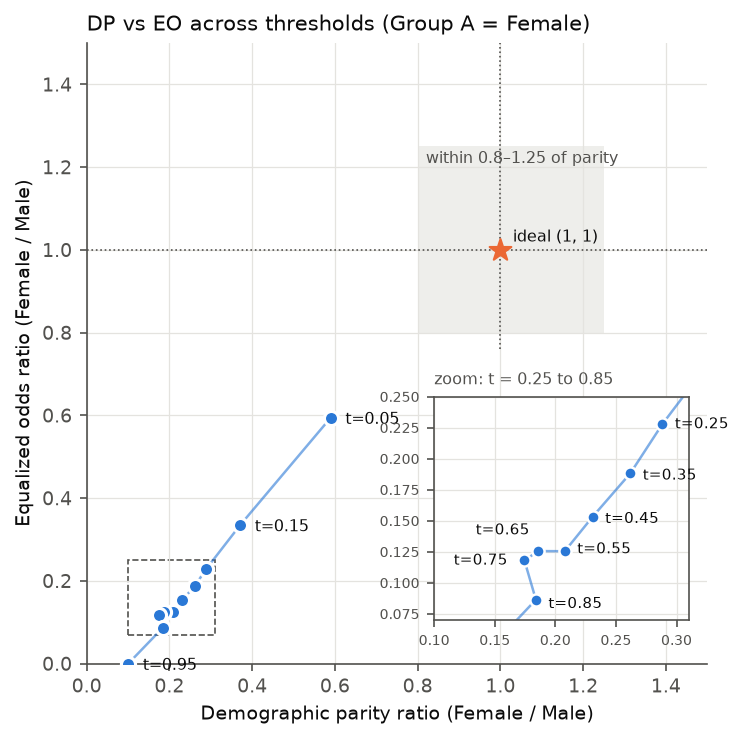

In [19]:
fig, ax = plt.subplots(figsize=(5.6, 5.0))
ax.fill_between([0.8, 1.25], 0.8, 1.25, color=GRID, alpha=0.6, lw=0)
ax.text(0.82, 1.21, "within 0.8–1.25 of parity", fontsize=7.5, color=MUTED)
ax.plot([0, 1.5], [1, 1], color=MUTED, lw=0.8, ls=":"); ax.plot([1, 1], [0.76, 1.5], color=MUTED, lw=0.8, ls=":")
ok = fair.dropna(subset=["DP", "EO"])
ax.plot(ok.DP, ok.EO, color=BLUE, lw=1.2, alpha=0.6)
ax.scatter(ok.DP, ok.EO, s=46, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
for _, r in ok[ok.threshold.isin([0.05, 0.15, 0.95])].iterrows():
    ax.annotate(f"t={r.threshold:.2f}", (r.DP, r.EO), xytext=(7, -3), textcoords="offset points", fontsize=7.5, color=INK)
# the thresholds 0.25-0.85 sit in a tight cluster, so they get a zoomed inset
x0, x1, y0, y1 = 0.10, 0.31, 0.07, 0.25
ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=MUTED, lw=0.8, ls="--"))
ins = ax.inset_axes([0.56, 0.07, 0.41, 0.36])
ins.plot(ok.DP, ok.EO, color=BLUE, lw=1.2, alpha=0.6)
ins.scatter(ok.DP, ok.EO, s=34, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3)
offs = {0.25: (6, -2), 0.35: (6, -3), 0.45: (6, -3), 0.55: (6, -1), 0.65: (-4, 8), 0.75: (-8, -2), 0.85: (6, -4)}
for _, r in ok.iterrows():
    t = round(r.threshold, 2)
    if t in offs:
        ins.annotate(f"t={t:.2f}", (r.DP, r.EO), xytext=offs[t], textcoords="offset points", fontsize=7, color=INK,
                     ha="right" if offs[t][0] < 0 else "left")
ins.set_xlim(x0, x1); ins.set_ylim(y0, y1); ins.tick_params(labelsize=6.5)
ins.set_title("zoom: t = 0.25 to 0.85", fontsize=7.5, color=MUTED, loc="left")
for sp in ins.spines.values(): sp.set_visible(True); sp.set_color(MUTED)
ax.scatter([1], [1], marker="*", s=120, color=ORANGE, zorder=4)
ax.annotate("ideal (1, 1)", (1, 1), xytext=(6, 4), textcoords="offset points", fontsize=7.5, color=INK)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_aspect("equal")
ax.set_xlabel("Demographic parity ratio (Female / Male)"); ax.set_ylabel("Equalized odds ratio (Female / Male)")
ax.set_title("DP vs EO across thresholds (Group A = Female)", fontsize=10, color=INK, loc="left")
fig.tight_layout(); fig.savefig(FIG / "part2_4_tradeoff.png"); plt.show()

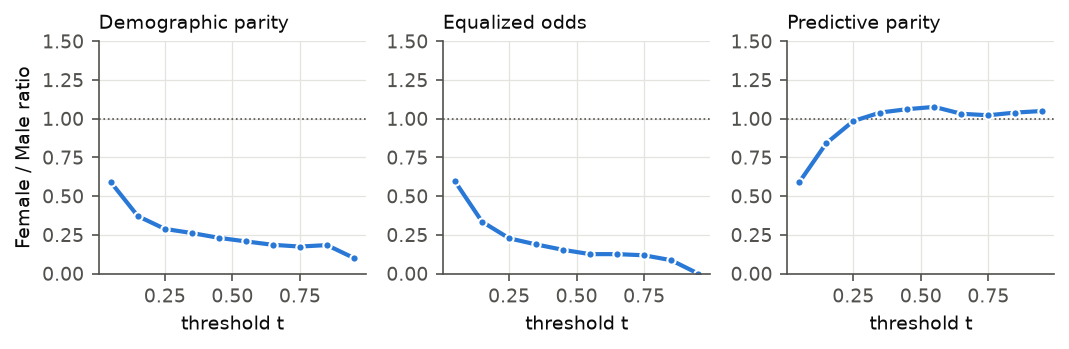

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4), sharex=True)
for ax, col, lab in zip(axes, ["DP", "EO", "PP"], ["Demographic parity", "Equalized odds", "Predictive parity"]):
    ax.axhline(1, color=MUTED, lw=0.8, ls=":")
    ax.plot(fair.threshold, fair[col], color=BLUE, lw=2, marker="o", ms=4, mec="white")
    ax.set_title(lab, fontsize=9, color=INK, loc="left"); ax.set_xlabel("threshold t")
    ax.set_ylim(0, 1.5)
axes[0].set_ylabel("Female / Male ratio")
fig.tight_layout(); fig.savefig(FIG / "part2_4_metrics_vs_threshold.png"); plt.show()

**Quantifying the trade-off.** For every pair of thresholds (t₁ → t₂) where DP gets closer to 1 while EO moves
further from 1, I compute the gain in DP, the loss in EO, and the cost W/Z. The pair with the biggest DP gain is
reported in the write-up.

In [21]:
pairs = []
ok = fair.dropna(subset=["DP", "EO"]).reset_index(drop=True)
for i, a in ok.iterrows():
    for j, b in ok.iterrows():
        if i == j: continue
        dist_dp_a, dist_dp_b = abs(1 - a.DP), abs(1 - b.DP)
        dist_eo_a, dist_eo_b = abs(1 - a.EO), abs(1 - b.EO)
        if dist_dp_b < dist_dp_a and dist_eo_b > dist_eo_a:
            z = 100 * (b.DP - a.DP) / a.DP; w = 100 * (a.EO - b.EO) / a.EO
            pairs.append({"from_t": a.threshold, "to_t": b.threshold, "DP_from": a.DP, "DP_to": b.DP,
                          "DP_gain_pct": z, "EO_from": a.EO, "EO_to": b.EO, "EO_loss_pct": w,
                          "cost_W_over_Z": w / z if z else np.nan})
trade = pd.DataFrame(pairs).sort_values("DP_gain_pct", ascending=False)
trade.round(4).to_csv(RES / "part2_4_tradeoff_pairs.csv", index=False)
N["trade_pairs"] = trade.round(4).head(10).to_dict(orient="records")
trade.round(3).head(10)

,from_t,to_t,DP_from,DP_to,DP_gain_pct,EO_from,EO_to,EO_loss_pct,cost_W_over_Z
0,0.65,0.55,0.186,0.208,11.856,0.126,0.126,0.107,0.009
1,0.75,0.85,0.174,0.184,5.426,0.118,0.086,26.754,4.931


In this data DP and EO mostly rise and fall together, so the sharper conflict is between those two and
predictive parity (and accuracy). The cell below records that DP-vs-PP trade-off and the group rates at the
default 0.5 cut-off.

In [22]:
f = fair.set_index("threshold")
def tradeoff(t1, t2, gain, loss):
    z = 100 * (f.loc[t2, gain] - f.loc[t1, gain]) / f.loc[t1, gain]
    w = 100 * abs(f.loc[t2, loss] - f.loc[t1, loss]) / f.loc[t1, loss]
    return {"from_t": t1, "to_t": t2, f"{gain}_from": f.loc[t1, gain], f"{gain}_to": f.loc[t2, gain], "gain_pct": z,
            f"{loss}_from": f.loc[t1, loss], f"{loss}_to": f.loc[t2, loss], "loss_pct": w, "cost": w / z,
            "acc_from": f.loc[t1, "acc_all"], "acc_to": f.loc[t2, "acc_all"]}
N["trade_dp_pp_025_005"] = tradeoff(0.25, 0.05, "DP", "PP")
N["trade_dp_eo_075_085"] = tradeoff(0.75, 0.85, "DP", "EO")
print(pd.Series(N["trade_dp_pp_025_005"]).round(4)); print(); print(pd.Series(N["trade_dp_eo_075_085"]).round(4))

yp50 = (pv >= 0.5).astype(int)
N["rates_t050"] = {"F": rates(yv[fem], yp50[fem]), "M": rates(yv[mal], yp50[mal]),
                   "acc_F": float((yp50[fem] == yv[fem]).mean()), "acc_M": float((yp50[mal] == yv[mal]).mean())}
print("\nGroup rates at t = 0.5:", pd.DataFrame({k: v for k, v in N["rates_t050"].items() if k in "FM"}).round(4), sep="\n")

from_t        0.2500
to_t          0.0500
DP_from       0.2883
DP_to         0.5900
gain_pct    104.6304
PP_from       0.9847
PP_to         0.5899
loss_pct     40.0930
cost          0.3832
acc_from      0.8069
acc_to        0.6080
dtype: float64

from_t       0.7500
to_t         0.8500
DP_from      0.1745
DP_to        0.1839
gain_pct     5.4261
EO_from      0.1181
EO_to        0.0865
loss_pct    26.7544
cost         4.9307
acc_from     0.8149
acc_to       0.7931
dtype: float64

Group rates at t = 0.5:
          F       M
sel  0.0608  0.2709
tpr  0.4165  0.6195
fpr  0.0161  0.1126
ppv  0.7652  0.7141


**Two real people from the test set** (used in Part 3, Q6): the woman who truly earns > $50K and the man who
does not, each with the predicted probability closest to 0.30. Their decisions at three thresholds:

In [23]:
show = ["age", "sex", "marital_status", "education", "occupation", "hours_per_week", "capital_gain", "y", "p"]
woman = T[(T.male == 0) & (T.y == 1)].assign(d=lambda d: (d.p - 0.30).abs()).sort_values("d").iloc[0]
man = T[(T.male == 1) & (T.y == 0)].assign(d=lambda d: (d.p - 0.30).abs()).sort_values("d").iloc[0]
people = pd.DataFrame([woman[show], man[show]], index=["Person F", "Person M"])
for t in [0.15, 0.25, 0.35, 0.45]:
    people[f"flag@{t}"] = (people.p >= t).astype(int)
N["example_people"] = people.astype(str).to_dict(orient="index")
people

,age,sex,marital_status,education,occupation,hours_per_week,capital_gain,y,p,flag@0.15,flag@0.25,flag@0.35,flag@0.45
Person F,37,Female,Never-married,Prof-school,Prof-specialty,55,0,1,0.301704,1,1,0,0
Person M,58,Male,Married-civ-spouse,HS-grad,Craft-repair,40,0,0,0.300000,1,1,0,0


In [24]:
# headline numbers the report quotes, plus the model coefficients
N["logit_coefs_train"] = model_b.params.round(4).to_dict()
N["ols_coefs_train"] = model_a.params.round(4).to_dict()
pd.DataFrame({"OLS (Model A)": model_a.params, "Logit (Model B)": model_b.params,
              "Logit p-value": model_b.pvalues}).round(4).to_csv(RES / "part1_model_coefficients.csv")

def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, float) and np.isnan(o): return None
    if isinstance(o, (np.integer,)): return int(o)
    return o
(RES / "numbers.json").write_text(json.dumps(to_py(N), indent=2))
print("Saved", len(N), "entries to results/numbers.json")
pd.DataFrame({"OLS (Model A)": model_a.params, "Logit (Model B)": model_b.params, "Logit p": model_b.pvalues}).round(3)

Saved 99 entries to results/numbers.json


,OLS (Model A),Logit (Model B),Logit p
const,0.061,-3.373,0.000
age,0.035,0.403,0.000
education_num,0.081,0.751,0.000
hours_per_week,0.031,0.351,0.000
log_cap_gain,0.082,0.513,0.000
log_cap_loss,0.039,0.233,0.000
male,0.037,0.115,0.021
married,0.287,2.337,0.000
native_us,0.012,0.302,0.000
race_Amer-Indian-Eskimo,-0.048,-0.443,0.029
